how to find uncertainties?  
bootstrap?  

tips:  

if modeling don't work, maybe forgot to preoprocess??  
must normalize and cut the initial part  
to be sure, tart in the middle, where the obscillation has already started  
bc the initial part screws it up  

or it could be a problem with the initial guesses

In [175]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

## Get data

In [176]:
path1 = '/home/gea/Desktop/Lab 1/pendolo_accoppiato_data/pendoloooooooo.txt'
path2 = '/home/gea/Desktop/Lab 1/pendolo_accoppiato_data/pendolooo-2.txt'
path3 = '/home/gea/Desktop/Lab 1/pendolo_accoppiato_data/pendoliiii-3.txt'
path4 = '/home/gea/Desktop/Lab 1/pendolo_accoppiato_data/pendolooooo-4.txt'
path5 = '/home/gea/Desktop/Lab 1/pendolo_accoppiato_data/pendoloooooo-5.txt'
path6 = '/home/gea/Desktop/Lab 1/pendolo_accoppiato_data/pendoliiiiiiiii.txt'

names=["t1", "pendulum1", "t2", "pendulum2"]

df1 = pd.read_csv(path1, header=None, delim_whitespace=True, comment='#', names=names)
df2 = pd.read_csv(path2, header=None, delim_whitespace=True, comment='#', names=names)
df3 = pd.read_csv(path3, header=None, delim_whitespace=True, comment='#', names=names)
df4 = pd.read_csv(path4, header=None, delim_whitespace=True, comment='#', names=names)
df5 = pd.read_csv(path5, header=None, delim_whitespace=True, comment='#', names=names)
df6 = pd.read_csv(path6, header=None, delim_whitespace=True, comment='#', names=names)

/tmp/ipykernel_15997/4271800311.py:10: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df1 = pd.read_csv(path1, header=None, delim_whitespace=True, comment='#', names=names)
/tmp/ipykernel_15997/4271800311.py:11: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df2 = pd.read_csv(path2, header=None, delim_whitespace=True, comment='#', names=names)
/tmp/ipykernel_15997/4271800311.py:12: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df3 = pd.read_csv(path3, header=None, delim_whitespace=True, comment='#', names=names)
/tmp/ipykernel_15997/4271800311.py:13: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df4 = p

In [177]:
# Look at the dataframe

df1.head()

,t1,pendulum1,t2,pendulum2
0,0.025,1023,0.051,473
1,0.076,1023,0.102,472
2,0.126,1023,0.152,472
3,0.178,1023,0.203,472
4,0.228,1022,0.253,472


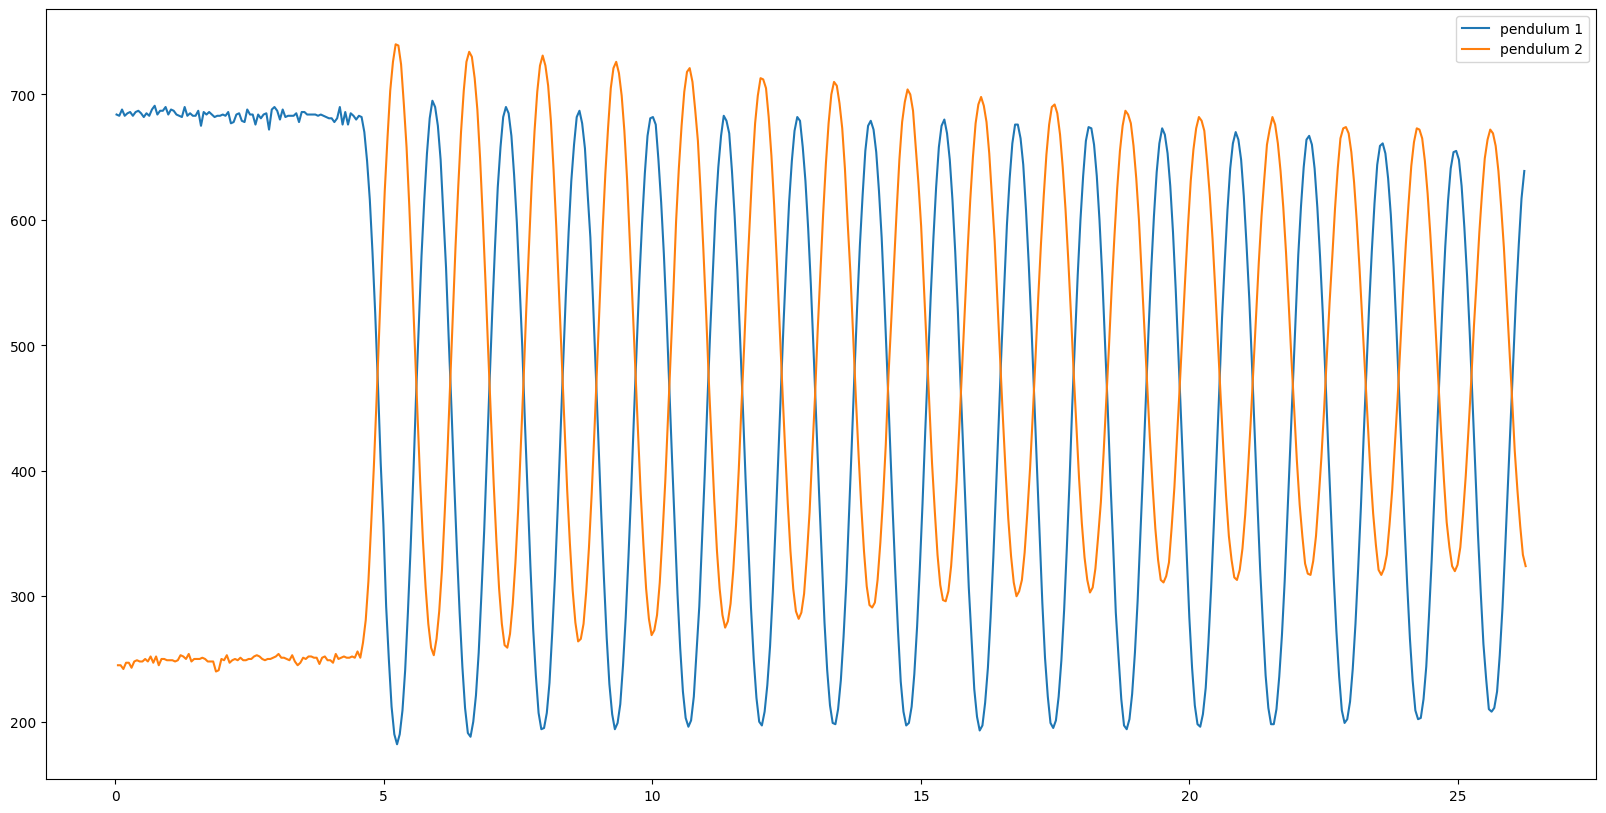

In [178]:
# Plot to heck what they are

dfn = df3   # here, change number of pendulum i want to see

x1 = dfn.t1
x2 = dfn.t2

y1 = dfn.pendulum1
y2 = dfn.pendulum2


plt.figure(figsize=(20,10))
plt.plot(x1,y1, label='pendulum 1')
plt.plot(x2,y2, label='pendulum 2')
plt.legend()

## Ready-made functions

In [179]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.signal import find_peaks

In [180]:
def damped_oscillator(x, A, lambda_, omega, phi, offset):
    return A * np.exp(-lambda_ * x) * np.sin(omega * x + phi) + offset

when using find_peaks

You can filter what counts as a peak using:

    height= → minimum amplitude

    distance= → minimum distance between peaks (in samples)

    prominence= → how much a peak stands out

In [181]:
def get_peaks(x,y, p=[(np.max(y1)-np.min(y1))/2, 0.01, 4.5, 0.0, np.mean(y1)]):
    '''pass x and y'''

    popt, _ = curve_fit(damped_oscillator, x, y, p0=p)

    x_dense = np.linspace(x.min(), x.max(), 5000)
    y_fit = damped_oscillator(x_dense, *popt)

    peak_indices, _ = find_peaks(y_fit)
    x_peaks = x_dense[peak_indices]
    y_peaks = y_fit[peak_indices]

    plt.figure(figsize=(10,5))
    plt.plot(x, y, '.', label='Data')
    plt.plot(x_dense, y_fit, label='Fitted model')
    plt.plot(x_peaks, y_peaks, 'ro', label='Detected peaks')
    plt.title('Pendolo semplice')
    plt.xlabel('Time')
    plt.ylabel('Amplitude')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    return x_peaks, y_peaks, popt

get_peaks has the offset parameter in the function it's trying to fit, so can fit the function even if the obscillation are not centered at amplitude 0  
however, normalizing before would make the convergence easier, and can pass 0 as an initial extimate for offset, so maybe do it?  

**Extimate initial param**

plot the points and see from the graph  

$A$: semi-amplitude of the first obscillation  

$\omega$: count number of obscillations in some time interval, $T=\frac{time \, interval}{number \, obscillations}$ and $\omega = \frac{2 \pi}{T}$ 

$\phi$: at $t=0$, if it's at extremity it's $\pm\frac{\pi}{2}$ (- if bottom, è is top) ???  

$\lambda$: time coord when ampltude has become a third, extimate by eye  

$offset$: mean, horizontal line at the center of obscillations  
if normalized before, it's 0  

In [182]:
def double_pendulums(t1,y1,t2,y2, p=[(np.max(y1)-np.min(y1))/2, 0.01, 4.5, 0.0, np.mean(y1)]):
    '''Handles independent timestamps for two pendulums: t1/y1 and t2/y2'''

    # === Fit for pendulum 1 ===
    params1, _ = curve_fit(damped_oscillator, t1, y1, p0=p)
    t1_dense = np.linspace(t1.min(), t1.max(), 5000)
    y1_fit = damped_oscillator(t1_dense, *params1)
    x_peaks1 = t1_dense[find_peaks(y1_fit)[0]]
    y_peaks1 = y1_fit[find_peaks(y1_fit)[0]]

    # === Fit for pendulum 2 ===
    params2, _ = curve_fit(damped_oscillator, t2, y2, p0=p)
    t2_dense = np.linspace(t2.min(), t2.max(), 5000)
    y2_fit = damped_oscillator(t2_dense, *params2)
    x_peaks2 = t2_dense[find_peaks(y2_fit)[0]]
    y_peaks2 = y2_fit[find_peaks(y2_fit)[0]]

    # === Plotting ===
    fig = plt.figure(figsize=(20, 10))
    ax1, ax2 = fig.subplots(2, 1, sharex=False, gridspec_kw=dict(hspace=0.05))

    ax1.plot(t1, y1, '.', label='Pendulum 1 data')
    ax1.plot(t1_dense, y1_fit, label='Fit 1')
    ax1.plot(x_peaks1, y_peaks1, 'ro', label='Peaks 1')
    ax1.set_ylabel('θ₁(t)')
    ax1.grid(True)
    ax1.legend()

    ax2.plot(t2, y2, '.', label='Pendulum 2 data')
    ax2.plot(t2_dense, y2_fit, label='Fit 2')
    ax2.plot(x_peaks2, y_peaks2, 'ro', label='Peaks 2')
    ax2.set_xlabel('Time')
    ax2.set_ylabel('θ₂(t)')
    ax2.grid(True)
    ax2.legend()

    plt.tight_layout()
    plt.show()

    return x_peaks1, y_peaks1, params1, x_peaks2, y_peaks2, params2

In [183]:
from scipy.signal import hilbert, find_peaks
from scipy.fft import fft, fftfreq

def analyze_beats(t, y):

    t = np.asarray(t)
    y = np.asarray(y)

    dt = t[1] - t[0]
    fs = 1 / dt
    N = len(t)

    # === 1. FFT to find dominant frequencies ===
    yf = fft(y)
    freqs = fftfreq(N, d=dt)
    idx = np.argsort(np.abs(yf[:N//2]))[::-1]  # Sort by magnitude

    # Take the two strongest positive frequencies
    dominant_freqs = freqs[idx[:2]]
    dominant_freqs = np.abs(dominant_freqs)
    omega1, omega2 = 2 * np.pi * dominant_freqs

    # === 2. Estimate ω_m and ω_b ===
    omega_m = (omega1 + omega2) / 2
    omega_b = abs(omega1 - omega2) / 2

    # === 3. Construct carrier and envelope ===
    carrier = np.cos(omega_m * t)
    envelope = np.abs(hilbert(y))  # analytical signal gives envelope

    # === 4. Plot ===
    plt.figure(figsize=(10, 6))
    plt.plot(t, y, label='Segnale')
    plt.plot(t, envelope, 'r--', label='Modulante') #envelope
    plt.plot(t, -envelope, 'r--')
    plt.plot(t, carrier, 'g:', label='Portante') #carrier
    plt.xlabel('Time')
    plt.ylabel('Amplitude')
    plt.title('Battimenti')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    print(f"Estimated omega1 = {omega1:.3f} rad/s")
    print(f"Estimated omega2 = {omega2:.3f} rad/s")
    print(f"=> omega_m (carrier) = {omega_m:.3f} rad/s")
    print(f"=> omega_b (envelope) = {omega_b:.3f} rad/s")

    return omega_m, omega_b

## Bootstrap

which one? bootstrap2 is the easy one i wrote, the one without number wrote by chatgpt, optimized for signal, has some checks and stuff??  

In [222]:
def bootstrap(x_data, y_data, model, p0=None, bounds=(-np.inf, np.inf), n_bootstrap=1000, max_param=1e3):
    """
    Bootstrap for parameter uncertainty estimation.

    Parameters:
        x_data, y_data: pandas Series or numpy arrays
        model: function to fit
        p0: initial guess for curve_fit
        bounds: bounds for curve_fit
        n_bootstrap: number of bootstrap iterations
        max_param: threshold to filter out unrealistic parameter values

    Returns:
        param_errors: standard deviation of parameters (robustly estimated)
    """
    param_samples = []

    for _ in range(n_bootstrap):
        indices = np.random.randint(0, len(x_data), len(x_data))
        x_sample = x_data.iloc[indices] if hasattr(x_data, 'iloc') else x_data[indices]
        y_sample = y_data.iloc[indices] if hasattr(y_data, 'iloc') else y_data[indices]

        try:
            popt, _ = curve_fit(model, x_sample, y_sample, p0=p0, bounds=bounds)
            if np.all(np.abs(popt) < max_param):  # Filter out wildly diverging fits
                param_samples.append(popt)
        except RuntimeError:
            continue

    param_samples = np.array(param_samples)

    if len(param_samples) == 0:
        raise RuntimeError("All bootstrap fits failed or were filtered out.")

    # Use robust IQR-based error estimate
    q75, q25 = np.percentile(param_samples, [75, 25], axis=0)
    iqr = q75 - q25
    param_errors = iqr / 1.349  # Approximate std for normal distribution

    return param_errors


In [216]:
def bootstrap2(x_data, y_data, model, p):
    '''Find uncertainties on the param fitted'''

    n_bootstrap = 1000
    param_samples = []

    # Bootstrap loop
    for _ in range(n_bootstrap):
        indices = np.random.randint(0, len(x_data), len(x_data))
        x_sample = x_data.iloc[indices]
        y_sample = y_data.iloc[indices]
        
        try:
            popt, _ = curve_fit(model, x_sample, y_sample, p0=p)
            param_samples.append(popt)
        except RuntimeError:
            continue  # Skip failed fits
    # so if it's too long, does what it can instead of losing everything  

    param_samples = np.array(param_samples)
    param_errors = np.std(param_samples, axis=0)

    print("Bootstrap parameter errors:", param_errors)
    return param_errors

## Preprocessing

In [185]:
# MASKING  
# if at first it's erratic or static, make it start after a while, else it won't fit properly  

def masking(x,y, start):
    mask = x >= start
    x_mask = x[mask]
    y_mask = y[mask]
    return x_mask, y_mask

def normalize(x): 
    '''only use it after masking'''
    signal = x - np.mean(x)
    return signal

In [186]:
def preprocess(x,y, start):
    '''give x,y, where to start the mask'''
    x_mask, y_mask = masking(x,y,start)
    signal = normalize(y_mask)
    return x_mask, signal

## Simple pendulum, damped or undamped

### Find peaks

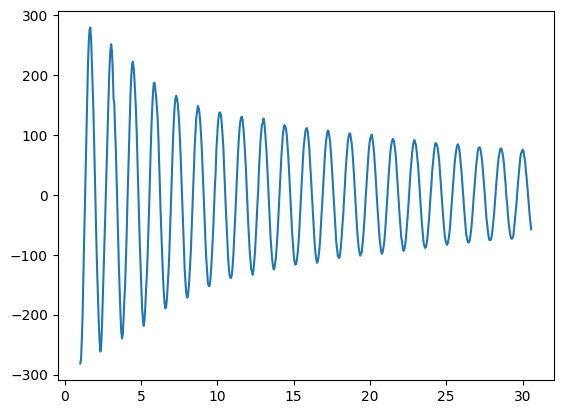

In [217]:
x = df6.t2
y = df6.pendulum2

# preprocessing - mask from 1  

x,y  = preprocess(x,y,1)
plt.plot(x, y)

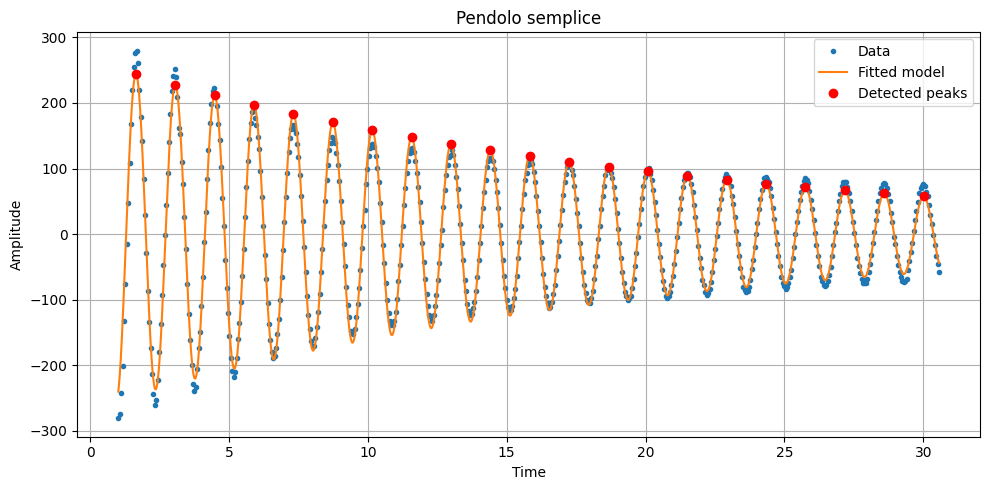

In [218]:
t_damped, theta_damped, params= get_peaks(x, y)

In [223]:
# as guess pass params, the ones computed in previous fit  
# bounds = ([0, 0, 0, -np.pi, -np.inf], [np.inf, 1, 20, np.pi, np.inf])
# if you want, put thisguess for the bound

errors = bootstrap(x,y,damped_oscillator, params)

### Find period

In [224]:
# Output

print("Fitted parameters:")
print(f"  Amplitude: {params[0]:.5} + {errors[0]:.5}")
print(f"  Damping: {params[1]:.5} + {errors[1]:.5}")
print(f"  Omega: {params[2]:.5}+ {errors[2]:.5}")
print(f"  Phase: {params[3]:.5}+ {errors[3]:.5}")
print(f"  Offset: {params[4]:.5}+ {errors[4]:.5}")

Fitted parameters:
  Amplitude: 266.32 + 4.2565
  Damping: 0.050625 + 0.0010782
  Omega: 4.4303+ 0.00083461
  Phase: 0.54401+ 0.012924
  Offset: -0.62158+ 0.46107


### Extimate decay time

**From fit**

In [143]:
print(f'Tau = {1/params[1]}')

Tau = 19.753176056636814


**In log graph**

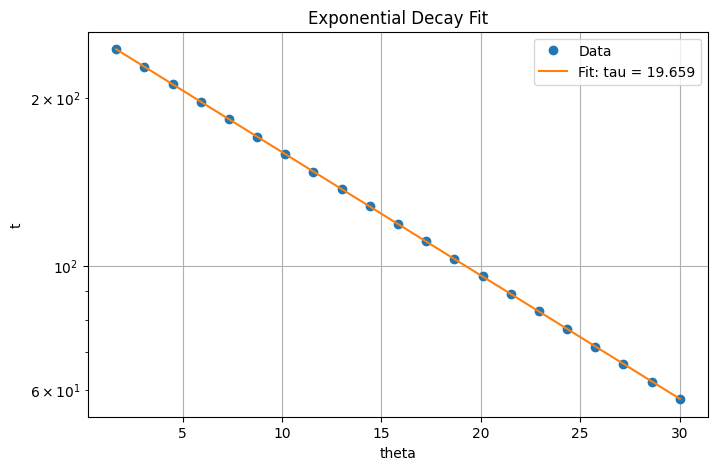

Estimated tau: 19.65949284117064


In [144]:
# data gotten from get_peaks
t = t_damped        # Time values
theta = theta_damped    # Corresponding theta values

# errors are so small they're trascurable  

def exponential_decay(t, theta0, tau):
    return theta0 * np.exp(-t / tau)

# guess = [theta[0], 1.0]
params, cov = curve_fit(exponential_decay, t, theta)  # po =g guess
theta0_fit, tau_fit = params



# Plot it
t_dense = np.linspace(t.min(), t.max(), 1000)
theta_fit = exponential_decay(t_dense, *params)

plt.figure(figsize=(8, 5))
plt.plot(t, theta, 'o', label='Data')
plt.plot(t_dense, theta_fit, label=f'Fit: tau = {tau_fit:.3f}')
plt.xlabel('theta')
plt.ylabel('t')
plt.title('Exponential Decay Fit')
plt.legend()
plt.yscale('log')

plt.grid(True)
plt.show()


print(f"Estimated tau: {tau_fit}")

### Check period

or could do 2pi /omega

In [145]:
period_damped = np.array([t_damped[i+1] - t_damped[i] for i in range(len(t_damped)-1)])  

In [146]:
print(f'Damped period: {np.mean(period_damped)}')

Damped period: 1.4182365873174636


## Obscillations phase

### In phase

In [160]:
# Get data

x1 = df2.t1
x2 = df2.t2

y1 = df2.pendulum1
y2 = df2.pendulum2

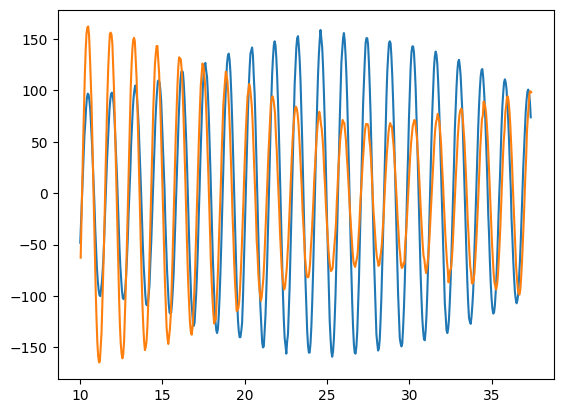

In [161]:
# preprocessing - choose start of mask

x1,y1 = preprocess(x1,y1, 10)
x2,y2 = preprocess(x2,y2, 10)

plt.plot(x1, y1, label='pendulum 1')
plt.plot(x2, y2, label='pendulum 2')


/tmp/ipykernel_15997/1840093643.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


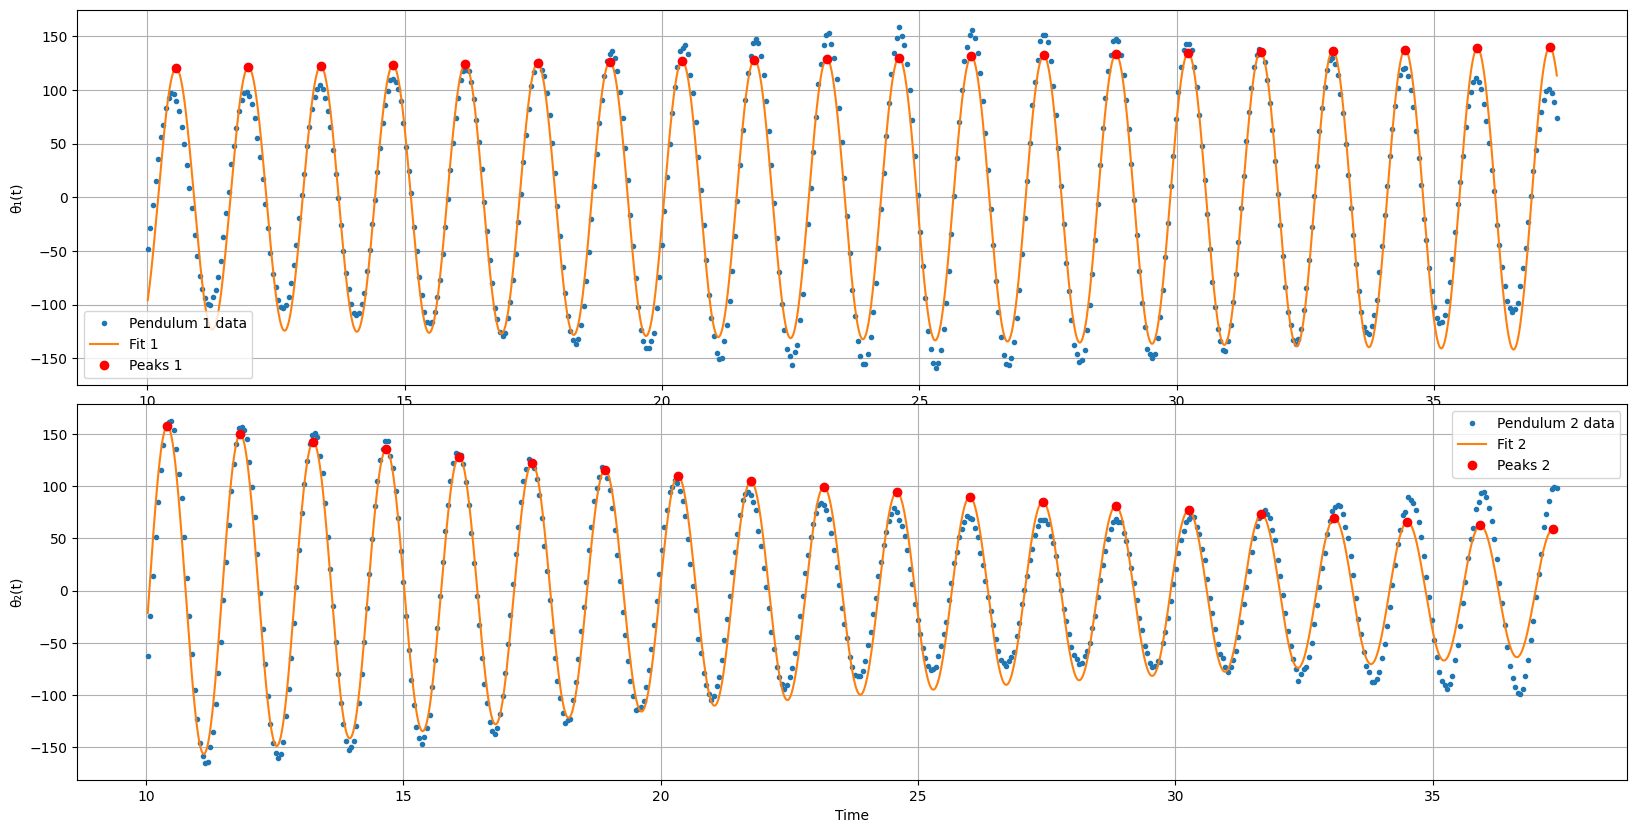

In [162]:
t1, theta1, param1, t2, theta2, param2 = double_pendulums(x1,y1,x2,y2)

In [150]:
print(f'omega_1 = {param1[2]} \n',
      f'omega_2 = {param2[2]}')

omega_1 = 4.474187921548813 
 omega_2 = 4.433866981575764


### Out of phase

In [163]:
# Get data

x1 = df3.t1
x2 = df3.t2

y1 = df3.pendulum1
y2 = df3.pendulum2

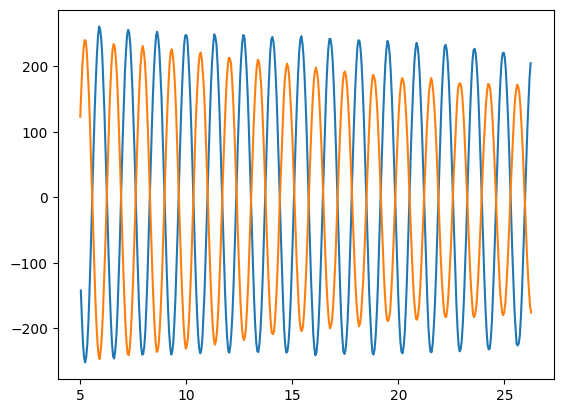

In [164]:
# preprocessing - choose start of mask

x1,y1 = preprocess(x1,y1, 5)
x2,y2 = preprocess(x2,y2, 5)

plt.plot(x1, y1, label='pendulum 1')
plt.plot(x2, y2, label='pendulum 2')

/tmp/ipykernel_15997/1840093643.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


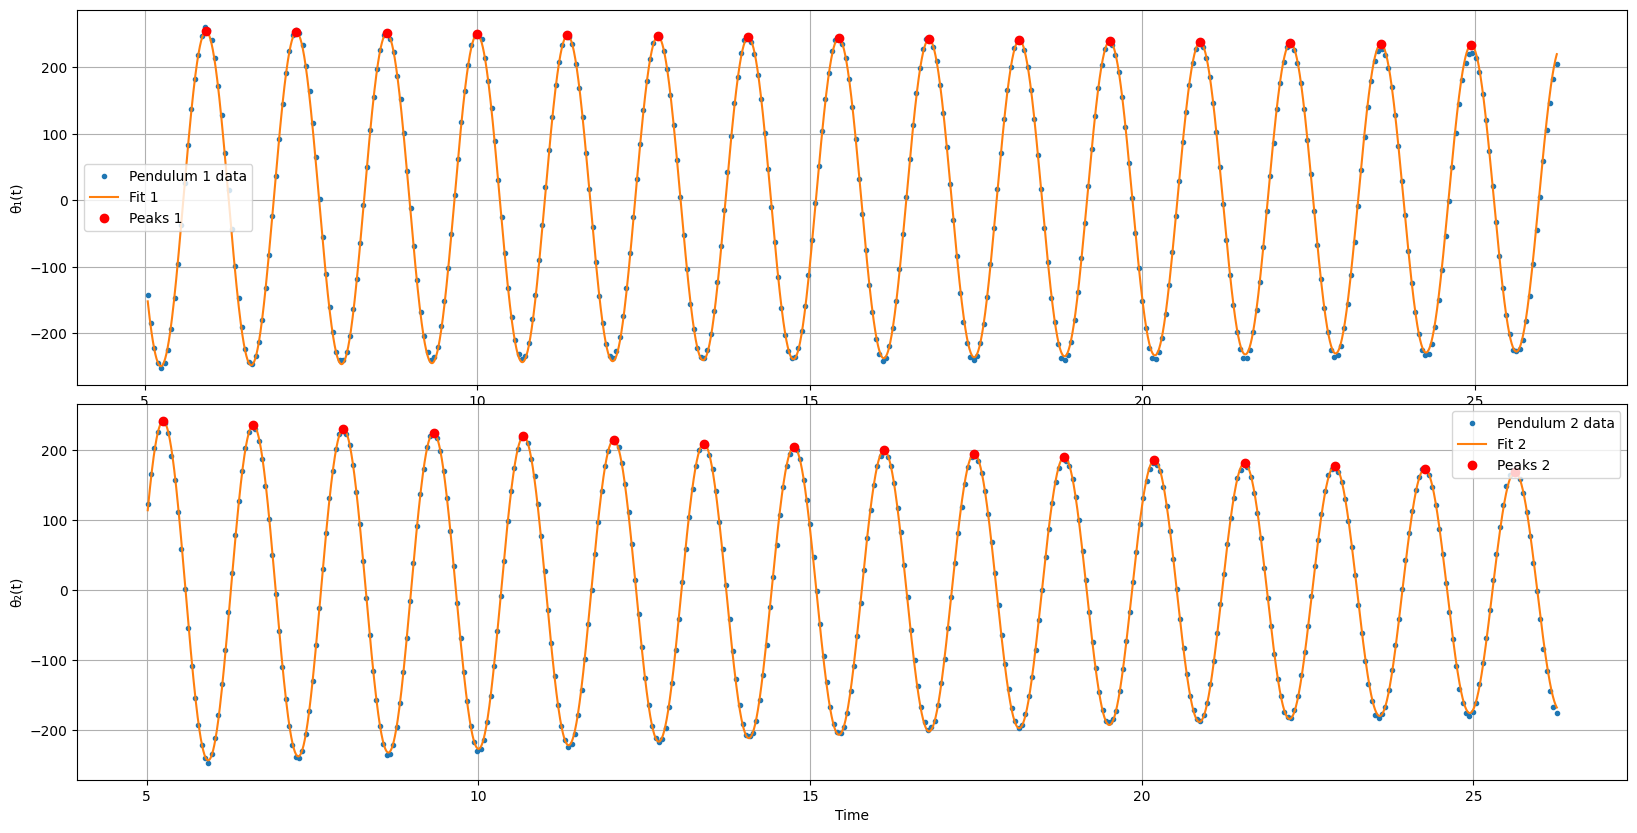

In [165]:
t1, theta1, param1, t2, theta2, param2 = double_pendulums(x1,y1,x2,y2)

In [154]:
print(f'omega_1 = {param1[2]} \n',
      f'omega_2 = {param2[2]}')

omega_1 = 4.623725029281428 
 omega_2 = 4.625571443407299


## Battimenti

In [166]:
# Get data

x1 = df4.t1
x2 = df4.t2

y1 = df4.pendulum1
y2 = df4.pendulum2

how did i find modulante and portante? what am i fitting with?  

In [167]:
# only need to plot one pendulum, if want can plot 2, but whatever  

x,y = preprocess(x1,y1,0)

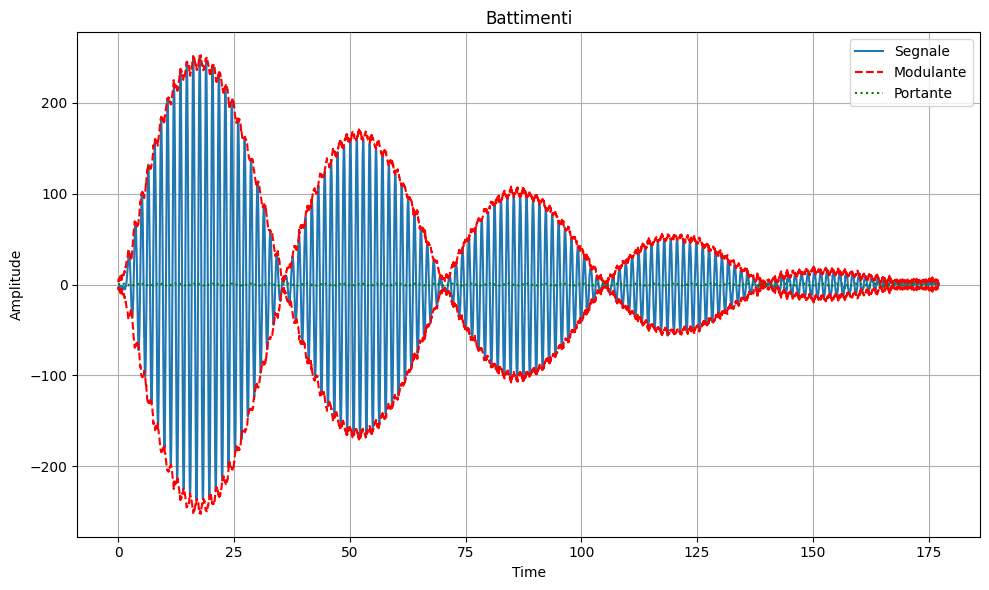

Estimated omega1 = 4.528 rad/s
Estimated omega2 = 4.707 rad/s
=> omega_m (carrier) = 4.618 rad/s
=> omega_b (envelope) = 0.090 rad/s


In [168]:
a,b = analyze_beats(x,y)